# Flux post-processing chain: IRGA72 NEE (2016-2026.09)

**notebook version**: `9` (26 Oct 2026). Adapted from the diive notebook `FluxPostProcessingChain.ipynb`.

## ℹ️ About this notebook

This notebook turns the CO2 flux (`FC`) of the closed-path **IRGA72** analyser into net ecosystem
exchange (`NEE`). It removes poor-quality records and outliers, fills the gaps, and splits NEE into
gross primary production (GPP) and ecosystem respiration (RECO). The steps follow the levels of the
Swiss FluxNet workflow:

| Level | What it does | Function |
|---|---|---|
| L2 | Quality flags from the EddyPro output | `run_level2` |
| L3.1 | Adds the storage term (`FC` becomes `NEE`) | `run_level31` |
| L3.2 | Removes outliers | `make_level32_detector` + `run_level32` |
| L3.3 | Removes records with weak turbulence (USTAR filter), for three thresholds | `run_level33_constant_ustar` |
| L4.1 | Fills the gaps with XGBoost | `run_level41_xgb` |
| L4.2 | Splits NEE into GPP and RECO (nighttime and daytime method of ONEFlux) | `run_level42_partitioning` |

Each step takes the data and returns a new copy, so a step can be repeated without running the
earlier ones again.

**Test mode.** The notebook currently runs on one year (`YEARS`) and skips Level 4.2
(`RUN_PARTITIONING`). Both are set in the settings cell.

The settings are those of the 2016-2024 notebooks in this folder (`01_FPC_L3.3_…` and
`03_FPC_L4.1_…`), rewritten for diive 0.91 and later.

***

## 📇 Data sources

The input is `20_MERGE_DATA/IRGA72/22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet` in the
external data folder. It holds the Level-1 fluxes of all 18 `IRGA72` runs together with the meteo
data of `10_METEO/30_PRODUCTS/99`, from 1 January 2016 00:15 to 30 September 2026 23:45
(`TIMESTAMP_MIDDLE`, UTC+01:00). The flux columns are empty before the first `IRGA72` record on
11 January 2016.

**Meteo drivers.** Gap-filling and partitioning use three complete meteo series: air temperature
(`TA_T1_47_1_HOMOGENIZED_gfXG`), vapour pressure deficit (`VPD_T1_47_1_HOMOGENIZED`) and incoming
shortwave radiation (`SW_IN_T1_47_1_gfXG`). Temperature and VPD are the homogenised versions, which
correct for the probe changes in 2016 and June 2026. The ONEFlux partitioning also needs *measured*
temperature and radiation. Step 6 builds them from the same series by keeping only the records
flagged as measured (`ISFILLED` code `0`).

**Periods to keep in mind.**

- **Start-up of the LI-7200 in 2016.** During the installation (11 to 22 January) and a period with
  too low a flow rate (1 March to 25 May), water in the filter lowered the fluxes. Level 3.2 removes
  both periods by hand, as the 2016-2024 notebooks did.
- **19 May to 7 June 2018.** There is no `FC`. The flow module of the analyser had failed, so this
  period was processed with the sonic anemometer only.
- **Wrong calibration gas, 14 December 2017 to 15 March 2019.** All `IRGA72` CO2 concentrations of
  this period were calibrated against the wrong reference gas. The correction, a factor of 0.974 on
  the concentration, has to be applied before the flux is calculated. It is not known whether the
  Level-1 runs applied it, so `FC` is not corrected here.

## ⚙️ Settings

In [1]:
# --- Source ------------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
SOURCEFILE = rf"{DATADIR}\20_MERGE_DATA\IRGA72\22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet"

# --- Testing -----------------------------------------------------------------------------------
# Years to process. None processes the whole record. A test run writes its own output file, so it
# never overwrites the result of a full run.
YEARS = [2025]
RUN_PARTITIONING = False  # Level 4.2, switched off while the earlier levels are checked

# --- Output ------------------------------------------------------------------------------------
OUTNAME = "01_FPPC_IRGA72_2016-2026.09"  # same name as this notebook
if YEARS:
    OUTNAME += f"_TEST_{'_'.join(str(_y) for _y in YEARS)}"
OUTPATH = rf"{DATADIR}\30_FLUX_PROCESSING_CHAIN\34_IRGA72_2016-2024"

# --- Site and flux -----------------------------------------------------------------------------
FLUXCOL = 'FC'  # CO2 flux of the closed-path LI-7200; no self-heating correction is needed
SITE_LAT = 47.478333  # CH-LAE
SITE_LON = 8.364389
UTC_OFFSET = 1  # timestamps are UTC+01:00 all year
NIGHTTIME_THRESHOLD = 20  # W m-2 potential radiation below this = nighttime
DAYTIME_ACCEPT_QCF_BELOW = 2  # keep QCF 0 and 1
NIGHTTIME_ACCEPT_QCF_BELOW = 2

# --- Level 2 -----------------------------------------------------------------------------------
LEVEL2_SETTINGS = {
    'signal_strength': {'apply': True,
                        'signal_strength_col': 'CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN',
                        'method': 'discard below',
                        'threshold': 60},
    'raw_data_screening_vm97': {'apply': True,
                                'spikes': True, 'amplitude': False, 'dropout': True,
                                'abslim': False, 'skewkurt_hf': False, 'skewkurt_sf': False,
                                'discont_hf': False, 'discont_sf': False},
    'ssitc': {'apply': True, 'setflag_timeperiod': None},
    'gas_completeness': {'apply': False},
    'spectral_correction_factor': {'apply': True},
    'angle_of_attack': {'apply': False, 'application_dates': []},
    'steadiness_of_horizontal_wind': {'apply': False},
}

# --- Level 3.2 ---------------------------------------------------------------------------------
# Start-up periods of the LI-7200 in 2016, removed by hand (date ranges, both ends included).
REMOVE_DATES = [
    ['2016-01-11', '2016-01-22'],
    ['2016-03-01', '2016-05-25'],
]

# --- Level 3.3 ---------------------------------------------------------------------------------
# Constant USTAR thresholds (m s-1), the 16th, 50th and 84th percentiles of the bootstrap
# detection of the 2016-2024 record (stage 32_). They have not been re-derived on the re-run
# Level-1 record of 2016-2026.09.
USTAR_THRESHOLDS = [0.271619922, 0.303628125, 0.339684084]
USTAR_SCENARIOS = ['CUT_16', 'CUT_50', 'CUT_84']

# --- Level 4.1 and 4.2: meteo drivers ----------------------------------------------------------
TA_F = 'TA_T1_47_1_HOMOGENIZED_gfXG'    # degC, complete
SW_IN_F = 'SW_IN_T1_47_1_gfXG'          # W m-2, complete
VPD_F = 'VPD_T1_47_1_HOMOGENIZED'       # kPa, complete
TA_FLAG = 'FLAG_TA_T1_47_1_ISFILLED'    # 0 = measured at 47 m
SW_IN_FLAG = 'FLAG_SW_IN_T1_47_1_ISFILLED'
TA_MEAS = 'TA_T1_47_1_HOMOGENIZED_MEASURED'  # built below from TA_F and TA_FLAG
SW_IN_MEAS = 'SW_IN_T1_47_1_MEASURED'        # built below from SW_IN_F and SW_IN_FLAG
FEATURES = [TA_F, SW_IN_F, VPD_F]

FLUX_UNITS = 'µmol m-2 s-1'
RANDUNC_COL = 'FC_RANDUNC_HF'  # random uncertainty of FC from EddyPro
NIGHT_Z = 3  # night values below -NIGHT_Z times their uncertainty are removed in Level 3.2

# 30-min NEE in umol CO2 m-2 s-1 -> gC m-2 per half-hour, for sums and cumulatives.
UMOL_TO_GC = 12.011 * 1e-6 * 1800

# XGBoost hyperparameters, at the production values suggested by the diive notebook.
XGB_SETTINGS = dict(n_estimators=350, max_depth=6, learning_rate=0.05,
                    early_stopping_rounds=10, random_state=42, n_jobs=-1, shap_max_rows=5000)

In [2]:
from datetime import datetime
import importlib.metadata
import warnings

import diive as dv
import pandas as pd
from diive.core.ml.feature_engineer import FeatureEngineer
from diive.flux.postprocessingchain import (
    add_driver,
    init_flux_data,
    make_level32_detector,
    nighttime_uncertainty,
    run_level2,
    run_level31,
    run_level32,
    run_level33_constant_ustar,
    run_level41_xgb,
    run_level42_partitioning,
    # Reporting over the finished chain
    plot_feature_ranks_per_year,
    plot_gapfilled_cumulative,
    plot_quality_heatmaps,
    plot_quality_timeseries,
    report_annual_sums,
    report_gapfilling_feature_importances,
    report_gapfilling_model_scores,
    report_gapfilling_poolyears,
    report_gapfilling_variables,
    report_traintest_details,
    report_traintest_model_scores,
)

# The notebook's inline backend renders each figure itself; diive's own fig.show() call can only
# warn that it cannot open a window.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-25 20:19:44
diive version: v0.93.0


## 📂 Load data

`init_flux_data` adds `SW_IN_POT`, `DAYTIME` and `NIGHTTIME` itself and stops if they already exist,
so they are removed from the input first.

In [3]:
df = dv.load_parquet(filepath=SOURCEFILE)
df = df.drop(columns=[c for c in ('SW_IN_POT', 'DAYTIME', 'NIGHTTIME') if c in df.columns])
if YEARS:
    df = df.loc[df.index.year.isin(YEARS)].copy()
    assert len(df) > 0, f"no records for {YEARS}"

for _c in [FLUXCOL, TA_F, SW_IN_F, VPD_F, TA_FLAG, SW_IN_FLAG,
           LEVEL2_SETTINGS['signal_strength']['signal_strength_col']]:
    assert _c in df.columns, f"{_c} is not in {SOURCEFILE}"
for _c in FEATURES:
    assert df[_c].notna().all(), f"driver {_c} has gaps"
print(f"{len(df):,} records x {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]}")
print(f"{FLUXCOL}: {df[FLUXCOL].notna().sum():,} records")

> Loaded .parquet file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\20_MERGE_DATA\IRG
A72\22.3_FLUXES_L1_IRGA72_and_METEO_2016-2026.09.parquet (0.331 seconds).

17,520 records x 347 columns, 2025-01-01 00:15:00 -> 2025-12-31 23:45:00
FC: 17,404 records


## Step 1: set up the data

Calculates the potential radiation, marks day and night, and stores the site coordinates that later
steps use. `*_ACCEPT_QCF_BELOW = 2` keeps records with quality flag 0 (all tests passed) and 1
(minor warnings).

In [4]:
data = init_flux_data(
    df=df,
    fluxcol=FLUXCOL,
    site_lat=SITE_LAT,
    site_lon=SITE_LON,
    utc_offset=UTC_OFFSET,
    nighttime_threshold=NIGHTTIME_THRESHOLD,
    daytime_accept_qcf_below=DAYTIME_ACCEPT_QCF_BELOW,
    nighttime_accept_qcf_below=NIGHTTIME_ACCEPT_QCF_BELOW,
)
print(data)

──────────────────────────────────── Initializing flux data: FC ────────────────────────────────────

> Detected base variable CO2 for FC. (CO2 was used to calculate FC.)

> Potential radiation calculated (SW_IN_POT)

> Day/night flags: DAYTIME, NIGHTTIME

FluxLevelData(
  flux        = 'FC'
  levels run  = []
  fpc_df      = 17520 rows x 5 cols
  columns     = [FC, USTAR, SW_IN_POT, DAYTIME, NIGHTTIME]
  filtered    = None (no level has run yet)
)


## Step 2: quality flags (Level 2)

The same tests as in the 2016-2024 notebooks: steady state and developed turbulence (SSITC), the
size of the spectral correction factor, the signal strength of the LI-7200 (records below 60 are
removed), and spikes and dropouts in the raw data (Vickers and Mahrt 1997). Gas completeness is not
tested.

In [5]:
data = run_level2(data, **LEVEL2_SETTINGS)
print(f'After L2: {data.filteredseries.dropna().count():,} valid records')

───────────────────────────────── Level 2: Quality Flag Expansion ──────────────────────────────────

> SSITC TEST: Generated new flag variable FLAG_L2_FC_SSITC_TEST, values taken from output variable
FC_SSITC_TEST ...

> SPECTRAL CORRECTION FACTOR TEST: Generating new flag variable FLAG_L2_FC_SCF_TEST, newly 
calculated from output variable FC_SCF, with flag 0 (good values) where FC_SCF < 2, flag 1 (ok 
values) where FC_SCF >= 2 and < 4, flag 2 (bad values) where FC_SCF >= 4...

> SIGNAL STRENGTH TEST: Generating new flag variable FLAG_L2_FC_SIGNAL_STRENGTH_TEST, newly 
calculated from output variable CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN, with flag 0 (good values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN >= 60, flag 2 (bad values) where 
CUSTOM_SIGNAL_STRENGTH_IRGA72_MEAN < 60 ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_SPIKE_HF_TEST, values taken from 
output variable CO2_VM97_TEST from position 1, based on CO2, with flag 0 (good values) where test 
passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test 
failed (for soft flags) ...

> RAW DATA TEST: Generated new flag variable FLAG_L2_FC_CO2_VM97_DROPOUT_HF_TEST, values taken 
from output variable CO2_VM97_TEST from position 3, based on CO2, with flag 0 (good values) where 
test passed, flag 2 (bad values) where test failed (for hard flags) or flag 1 (ok values) where test
failed (for soft flags) ...

After L2: 13,768 valid records


### 📊 Plot: Level-2 quality flag over time

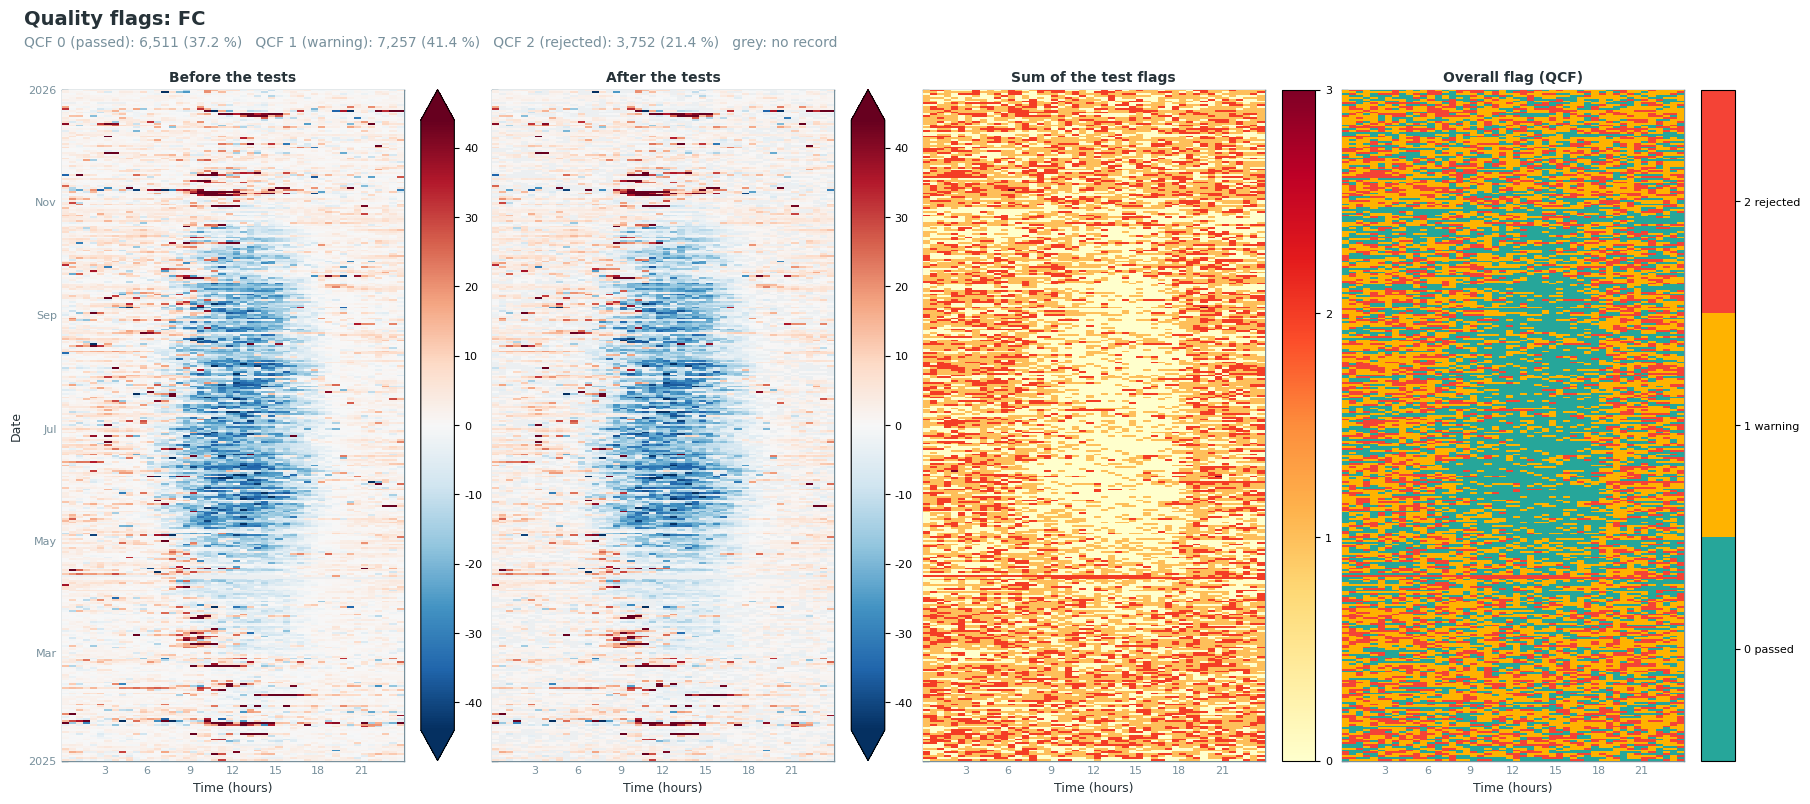

In [6]:
data.levels.level2_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-2 test

In [7]:
data.levels.level2_qcf.report_qcf_flags()

Test flags: FC
Measured records: 17,404 of 17,520
Missing records: 116 (0.66 %), flagged by the missing-values test
                                                Pass    Warn    Fail    Fail      Not
Test                        Period   Tested      (0)     (1)     (2)       %   tested
─────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                 all      17,404    6,514   7,258   3,632   20.87        0
                            day       8,651    3,915   3,350   1,386   16.02        0
                            night     8,753    2,599   3,908   2,246   25.66        0
                                                                                     
L2_FC_SCF                   all      17,404   17,393       8       3    0.02        0
                            day       8,651    8,646       5       0    0.00        0
                            night     8,753    8,747       3       3    0.03        0
                                                                                     
L2_FC_SIGNAL_STRENGTH       all      17,404   17,403       0       1   <0.01        0
                            day       8,651    8,651       0       0    0.00        0
                            night     8,753    8,752       0       1    0.01        0
                                                                                     
L2_FC_CO2_VM97_SPIKE_HF     all      17,404   17,404       0       0    0.00        0
                            day       8,651    8,651       0       0    0.00        0
                            night     8,753    8,753       0       0    0.00        0
                                                                                     
L2_FC_CO2_VM97_DROPOUT_HF   all      17,404   17,404       0       0    0.00        0
                            day       8,651    8,651       0       0    0.00        0
                            night     8,753    8,753       0       0    0.00        0

## Step 3: storage term (Level 3.1)

Adds the storage term to the flux (`NEE = FC + SC_SINGLE`). Gaps in the storage term are filled first.

In [8]:
data = run_level31(data, gapfill_storage_term=True, set_storage_to_zero=False)
print(f'After L3.1: {data.filteredseries.dropna().count():,} valid records '
      f'(col: {data.filteredseries.name})')

────────────────────────────────── Level 3.1: Storage Correction ───────────────────────────────────

> Calculating storage-corrected flux NEE_L3.1 from flux FC + storage term SC_SINGLE

After L3.1: 13,768 valid records (col: NEE_L3.1_QCF)


## Step 4: outlier removal (Level 3.2)

Four tests:

1. Remove the 2016 start-up periods of the LI-7200 by hand. Skipped when the processed years do not
   include them.
2. Hampel filter on the double differences of neighbouring records. It finds single spikes.
3. Hampel filter on the values. It finds records far from the 13-day median of their period, such as
   a run of high values that the double differences do not catch.
4. Remove nighttime values clearly below zero, see *Negative values at night* below.

Both Hampel filters use 5.5 sigma by day and by night, in a 13-day window.

Each test first draws its plot. Check the plot, then run the cell below it, `sod.addflag()`, to
accept the test. A test that is not accepted removes nothing.

diive has more outlier tests. The table at the end of this step lists them. To add one, call its
method on `sod` in a new cell before *Apply the Level-3.2 flags*, check its plot, and accept it with
`sod.addflag()` in the cell after it.

In [9]:
data, sod = make_level32_detector(data)

### 📊 Plot: 2016 start-up periods, removed by hand

In [10]:
# Only the date ranges that overlap the processed records; none means no test and no flag.
_first, _last = data.full_df.index[0], data.full_df.index[-1]
_remove = [_d for _d in REMOVE_DATES
           if pd.Timestamp(_d[0]) <= _last and pd.Timestamp(_d[1]) + pd.Timedelta('1D') > _first]
if _remove:
    sod.flag_manualremoval_test(remove_dates=_remove, showplot=True, verbose=True)
else:
    print(f"No manual removal dates in {_first:%Y-%m-%d} - {_last:%Y-%m-%d}; test skipped.")

No manual removal dates in 2025-01-01 - 2025-12-31; test skipped.


In [11]:
if _remove:
    sod.addflag()  # accept the manual removal

### 📊 Plot: Hampel filter on double differences

[Dt/Nt] ITER #01 | Outliers:   476 (  3.46%) | Day:   239 | Night:   237

[Dt/Nt] ITER #02 | Outliers:    86 (  0.65%) | Day:    47 | Night:    39

[Dt/Nt] ITER #03 | Outliers:    21 (  0.16%) | Day:     8 | Night:    13

[Dt/Nt] ITER #04 | Outliers:     3 (  0.02%) | Day:     0 | Night:     3

[Dt/Nt] ITER #05 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

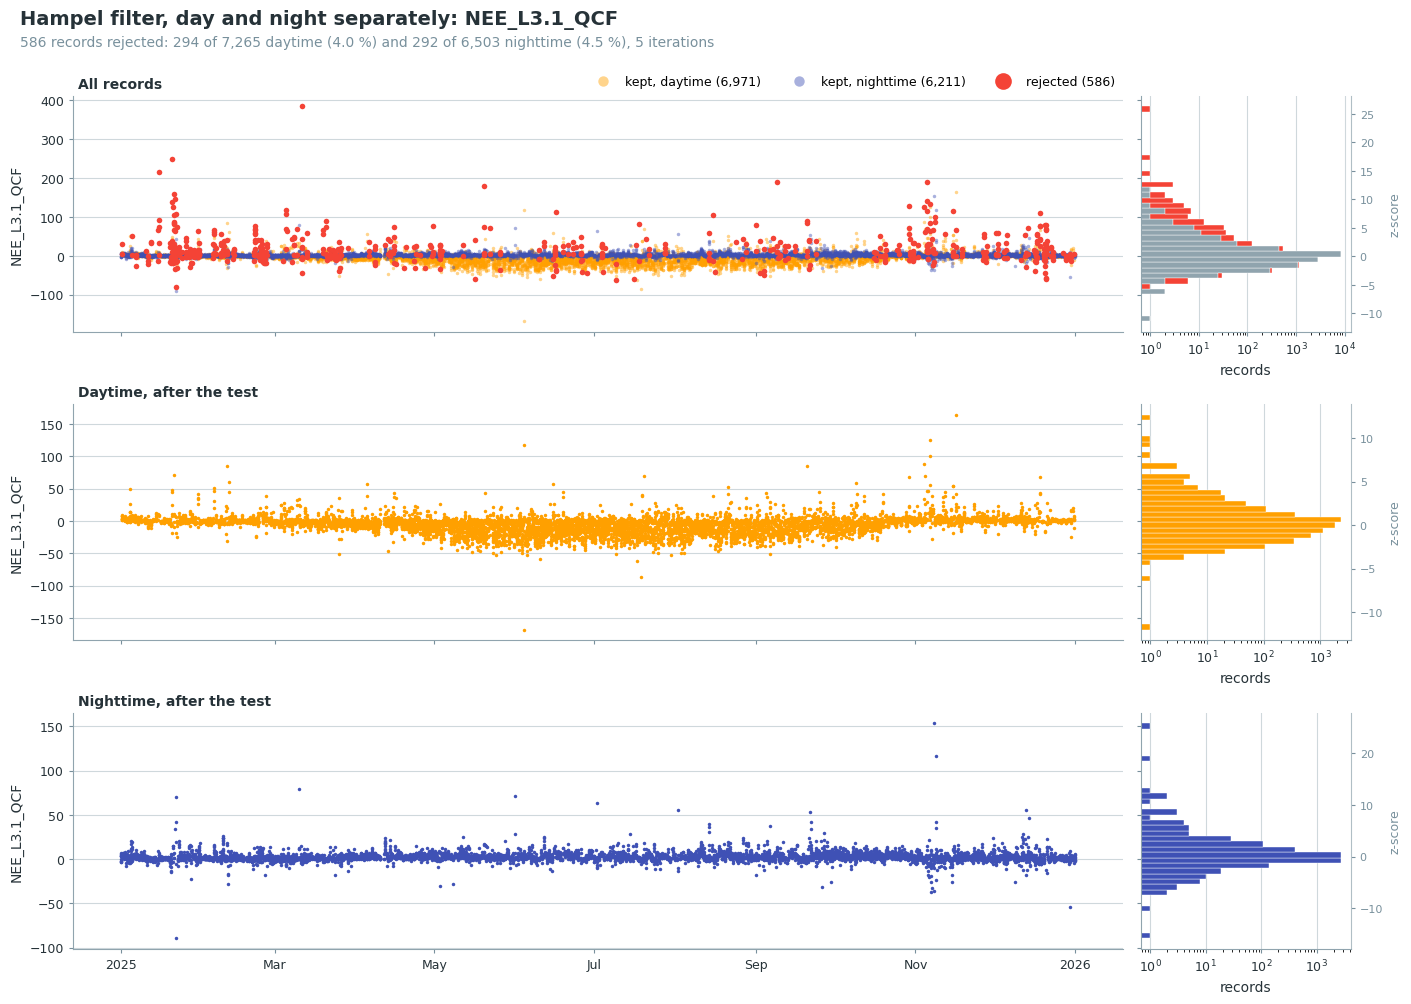

In [12]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=True,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [13]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_TEST to flag data

### 📊 Plot: Hampel filter on values

[Dt/Nt] ITER #01 | Outliers:   255 (  1.93%) | Day:    94 | Night:   161

[Dt/Nt] ITER #02 | Outliers:    28 (  0.22%) | Day:    10 | Night:    18

[Dt/Nt] ITER #03 | Outliers:     4 (  0.03%) | Day:     2 | Night:     2

[Dt/Nt] ITER #04 | Outliers:     0 (  0.00%) | Day:     0 | Night:     0

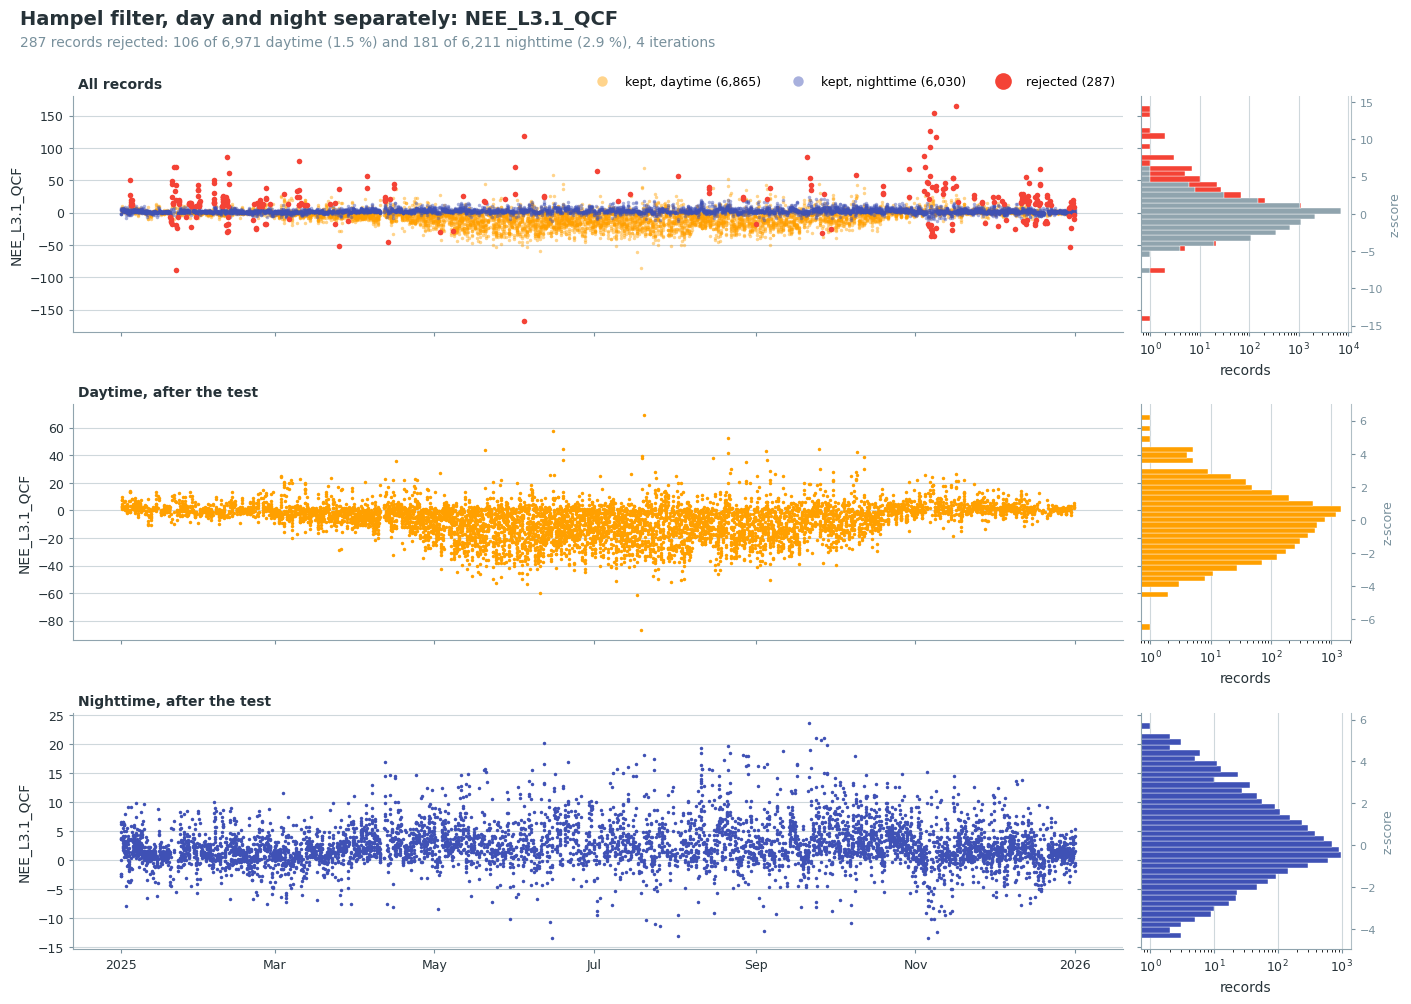

In [14]:
sod.flag_outliers_hampel_test(window_length=48 * 13, n_sigma=5.5, use_differencing=False,
                              separate_day_night=True, showplot=True, verbose=True, repeat=True)

In [15]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2_TEST to flag data

### Negative values at night

At night there is no photosynthesis, so NEE is respiration and its true value is zero or above. A
measured value can still be negative: random noise around a small respiration pushes some records
below zero. Such a value is plausible as long as it lies within a few times its random uncertainty
(sigma) of zero. A value below `-NIGHT_Z * sigma` is not, and test 4 removes it. Daytime values are
not tested, because by day both signs are real.

Removing every negative value would cut off one side of the noise and push nighttime NEE up, so the
test removes only the values noise cannot explain. Its plot reports how many of the removed records
noise alone would have produced: if that number is small, the test removes errors, not noise.

Sigma is the larger of two uncertainties for each record:

- **FS**: the uncertainty EddyPro gives for each half-hour (`FC_RANDUNC_HF`). It covers only the
  sampling error of that half-hour's covariance, so it is small.
- **PAS20**: the random uncertainty of FLUXNET2015 and ONEFlux, the spread of measured fluxes under
  similar conditions within days of each record. It covers the whole random error. It is computed
  from the records the Hampel filters kept, so that outliers do not widen it.

With the larger of the two, a value counts as clearly below zero only if neither explains it.

### 📋 Table: random uncertainty of the nighttime records

In [16]:
sigma = nighttime_uncertainty(data, sod, randunc_col=RANDUNC_COL, ta=TA_F, vpd=VPD_F, swin=SW_IN_F)

Random uncertainty of the 6,030 nighttime records
uncertainty   median at night   below -2 sigma   below -3 sigma
───────────────────────────────────────────────────────────────
FS                       0.68      525 (8.7 %)      367 (6.1 %)
PAS20                    2.97       38 (0.6 %)        4 (0.1 %)
MAX                      2.99       33 (0.5 %)        4 (0.1 %)
FS: EddyPro, sampling error of each half-hour. PAS20: spread of similar measurements (ONEFlux). MAX:
the larger of the two.

### 📊 Plot: nighttime values clearly below zero

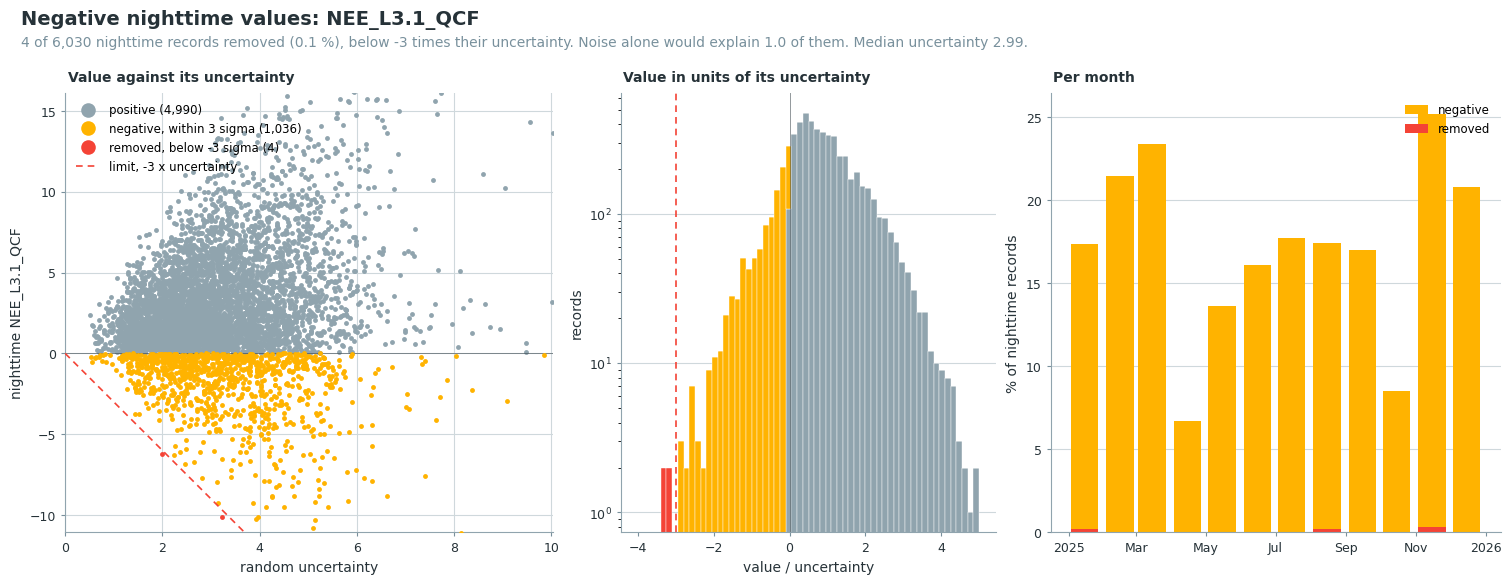

In [17]:
sod.flag_outliers_negative_night_test(uncertainty=sigma['MAX'], z=NIGHT_Z, showplot=True, verbose=True)

In [18]:
sod.addflag()  # accept this test

> ++Added flag column FLAG_L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHT_TEST to flag data

### 📋 Table: outlier tests available in diive

Every test of the outlier detector `sod`, with the ones used above marked. `help(sod.<method>)`
shows the settings of a test.

In [19]:
_used = {'flag_manualremoval_test', 'flag_outliers_hampel_test',
         'flag_outliers_negative_night_test'}
_rows = []
for _name in sorted(dir(type(sod))):
    if not (_name.startswith('flag_') and _name.endswith('_test')):
        continue
    # The first sentence of the docstring, which may run over two lines.
    _doc = (getattr(type(sod), _name).__doc__ or '').strip().split('\n\n')[0]
    _first = ' '.join(_doc.split()).split('. ')[0].rstrip('.')
    _rows.append({'method': f'sod.{_name}()', 'what it does': _first,
                  'used here': 'yes' if _name in _used else ''})
display(pd.DataFrame(_rows).set_index('method'))

,what it does,used here
method,,
sod.flag_manualremoval_test(),Flag specified records for removal,yes
sod.flag_missingvals_test(),Flag missing records in the data (flag 2 where...,
sod.flag_outliers_abslim_test(),Identify outliers based on absolute limits,
sod.flag_outliers_hampel_test(),Identify outliers in a sliding window based on...,yes
sod.flag_outliers_increments_zcore_test(),Identify outliers based on the z-score of reco...,
sod.flag_outliers_localsd_test(),Identify outliers based on standard deviation ...,
sod.flag_outliers_lof_test(),Local outlier factor detection (global or sepa...,
sod.flag_outliers_negative_night_test(),Flag nighttime values below -z times their ran...,yes
sod.flag_outliers_trim_low_test(),Flag values below a given absolute limit as ou...,


### Apply the Level-3.2 flags

In [20]:
data = run_level32(data, outlier_detector=sod)
print(f'After L3.2: {data.filteredseries.dropna().count():,} valid records')

────────────────────────────── Level 3.2: Stepwise Outlier Detection ───────────────────────────────

After L3.2: 12,891 valid records


### 📊 Plot: all removed outliers

Every record Level 3.2 removed, coloured by the test that removed it, with the share removed per
month and per hour of the day.

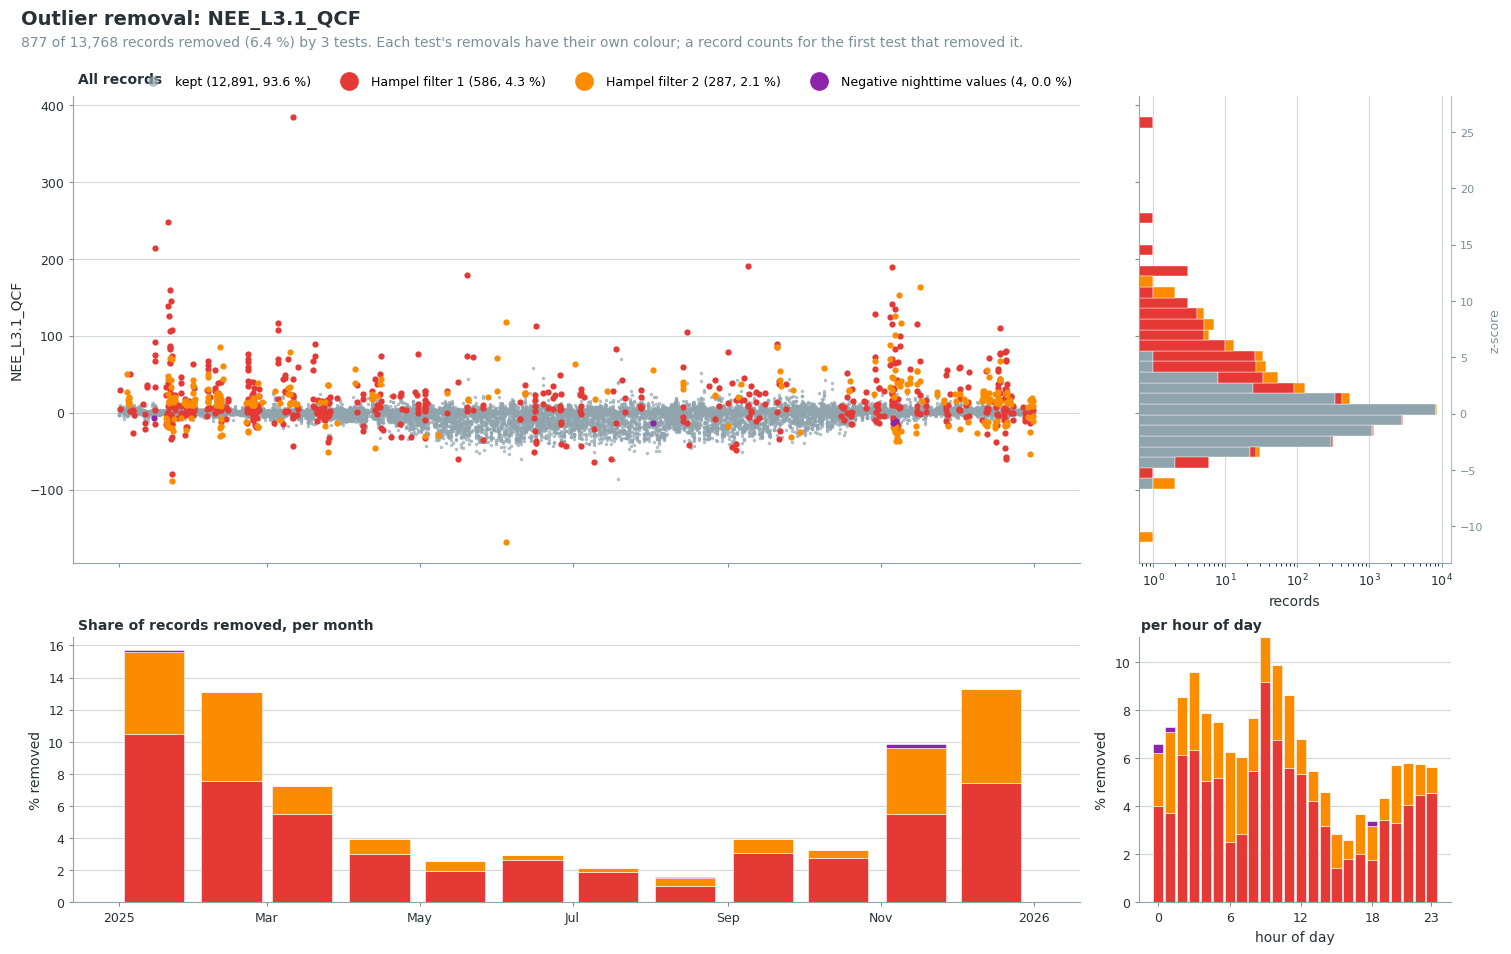

In [21]:
data.levels.level32.showplot_overview();

### 📊 Plot: Level-3.2 quality flag over time

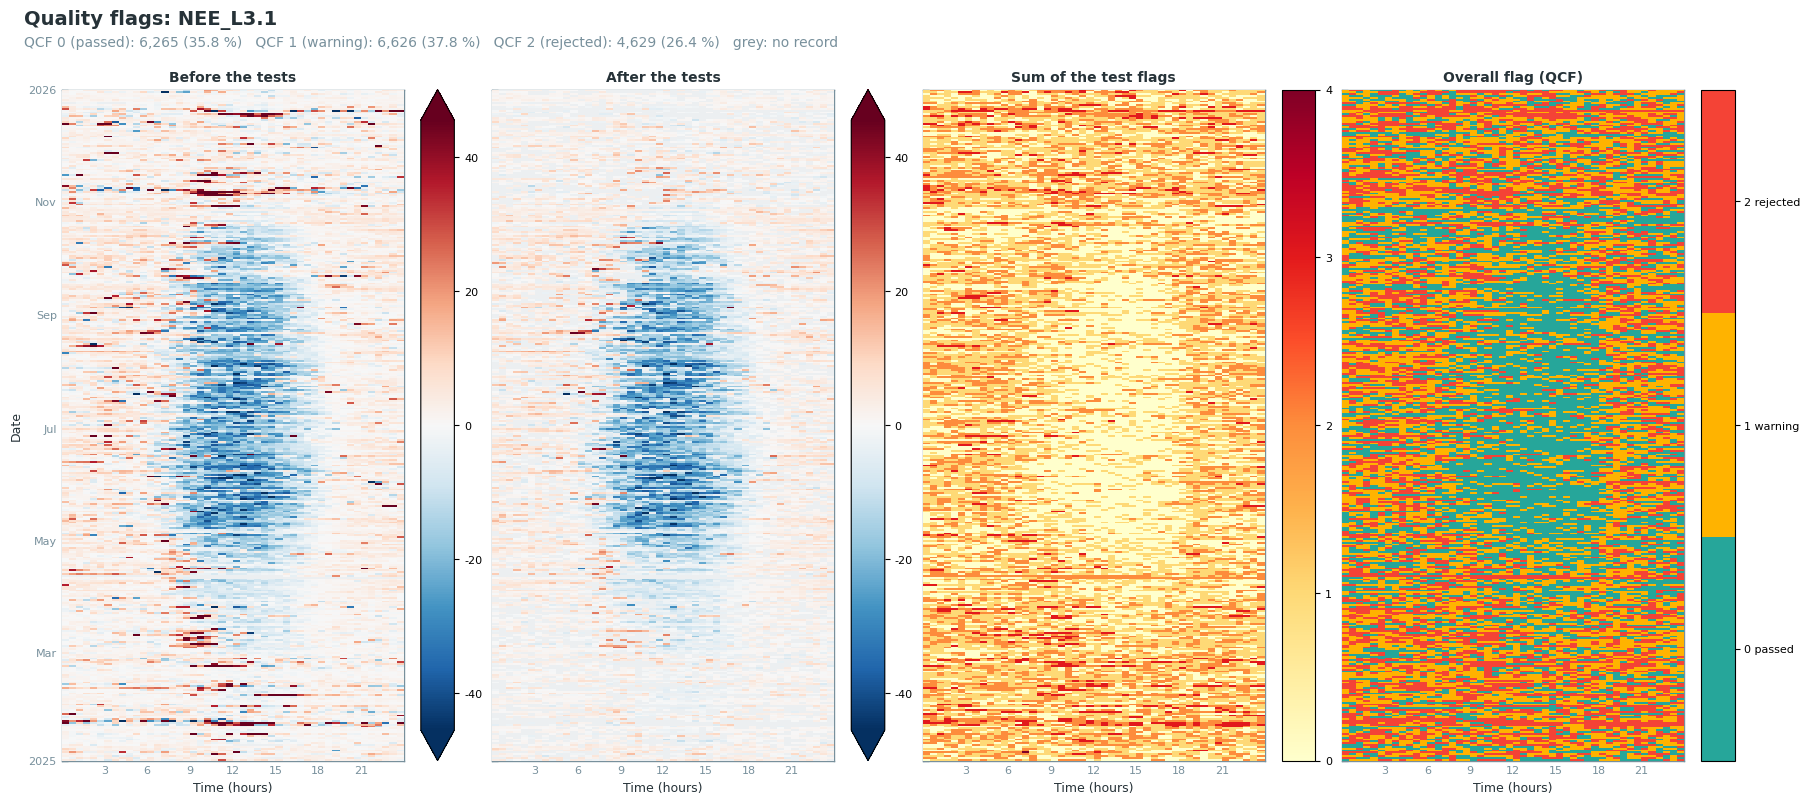

In [22]:
data.levels.level32_qcf.showplot_qcf_heatmaps()

### 📋 Table: result of each Level-3.2 test

In [23]:
data.levels.level32_qcf.report_qcf_flags()

Test flags: NEE_L3.1
Measured records: 17,404 of 17,520
Missing records: 116 (0.66 %), flagged by the missing-values test
                                                         Pass    Warn    Fail    Fail      Not
Test                                 Period   Tested      (0)     (1)     (2)       %   tested
──────────────────────────────────────────────────────────────────────────────────────────────
L2_FC_SSITC                          all      17,404    6,514   7,258   3,632   20.87        0
                                     day       8,651    3,915   3,350   1,386   16.02        0
                                     night     8,753    2,599   3,908   2,246   25.66        0
                                                                                              
L2_FC_SCF                            all      17,404   17,393       8       3    0.02        0
                                     day       8,651    8,646       5       0    0.00        0
                                     night     8,753    8,747       3       3    0.03        0
                                                                                              
L2_FC_SIGNAL_STRENGTH                all      17,404   17,403       0       1   <0.01        0
                                     day       8,651    8,651       0       0    0.00        0
                                     night     8,753    8,752       0       1    0.01        0
                                                                                              
L2_FC_CO2_VM97_SPIKE_HF              all      17,404   17,404       0       0    0.00        0
                                     day       8,651    8,651       0       0    0.00        0
                                     night     8,753    8,753       0       0    0.00        0
                                                                                              
L2_FC_CO2_VM97_DROPOUT_HF            all      17,404   17,404       0       0    0.00        0
                                     day       8,651    8,651       0       0    0.00        0
                                     night     8,753    8,753       0       0    0.00        0
                                                                                              
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL     all      13,768   13,182       0     586    4.26    3,636
                                     day       7,265    6,971       0     294    4.05    1,386
                                     night     6,503    6,211       0     292    4.49    2,250
                                                                                              
L3.2_NEE_L3.1_QCF_OUTLIER_HAMPEL_2   all      13,182   12,895       0     287    2.18    4,222
                                     day       6,971    6,865       0     106    1.52    1,680
                                     night     6,211    6,030       0     181    2.91    2,542
                                                                                              
L3.2_NEE_L3.1_QCF_OUTLIER_NEGNIGHT   all      12,895   12,891       0       4    0.03    4,509
                                     day       6,865    6,865       0       0    0.00    1,786
                                     night     6,030    6,026       0       4    0.07    2,723

## Step 5: USTAR filter (Level 3.3)

Removes records with weak turbulence, where the friction velocity (USTAR) is below a threshold. There
are three scenarios, one per threshold: the 16th, 50th and 84th percentile of the threshold
detection. From here on each scenario has its own series, so `data.filteredseries` is empty.

In [24]:
data = run_level33_constant_ustar(
    data,
    thresholds=USTAR_THRESHOLDS,
    threshold_labels=USTAR_SCENARIOS,
    showplot=False,
    verbose=True,
)

for _scen in USTAR_SCENARIOS:
    _flux = data.levels.filteredseries_level33_qcf[_scen]
    _flux_hq = data.levels.filteredseries_level33_hq[_scen]  # QCF=0 only
    print(f'After L3.3 ({_scen}): {_flux.dropna().count():,} accepted | '
          f'{_flux_hq.dropna().count():,} high-quality')

──────────────────────────────────── Level 3.3: USTAR Filtering ────────────────────────────────────

> QCF computed for USTAR scenario CUT_16

> QCF computed for USTAR scenario CUT_50

> QCF computed for USTAR scenario CUT_84

After L3.3 (CUT_16): 9,579 accepted | 5,381 high-quality
After L3.3 (CUT_50): 8,962 accepted | 5,129 high-quality
After L3.3 (CUT_84): 8,263 accepted | 4,811 high-quality


### 📋 Table: gaps per USTAR scenario

The gaps left after Level 3.3, which the gap-filling has to fill. A long gap lasts at least one day (48 records).

In [25]:

from diive.analysis import GapStats

_rows = {}
for _scen, _series in data.levels.filteredseries_level33_qcf.items():
    _gs = GapStats(_series, long_gap_records=48)
    _sm = _gs.summary
    _rows[_scen] = {
        'missing %': round(100 * _series.isna().mean(), 1),
        'gaps': len(_gs.results),
        'long gaps': _sm['n_long_gaps'],
        'longest gap (days)': round(_gs.results['GAP_LENGTH'].max() / 48, 1),
        'worst month': pd.Timestamp(2000, _sm['worst_month'], 1).strftime('%b'),
        'worst month missing %': round(_sm['worst_month_missing_pct'], 1),
    }
display(pd.DataFrame(_rows).T)


,missing %,gaps,long gaps,longest gap (days),worst month,worst month missing %
CUT_16,45.3,2327,5,1.3,Dec,62.5
CUT_50,48.8,2219,6,2.4,Dec,67.1
CUT_84,52.8,2107,9,3.4,Dec,70.6


## Step 6: meteo drivers and model features

The ONEFlux partitioning needs measured temperature and radiation. These are the complete driver
series, restricted to the records measured at 47 m. `add_driver` puts them into `data.full_df`,
where Levels 4.1 and 4.2 look for their drivers.

The feature engineer adds lagged values, rolling statistics and time terms to the drivers. It is
built once and passed to XGBoost. `target_col` is only a placeholder.

In [26]:
_ta_meas = df[TA_F].where(df[TA_FLAG] == 0).rename(TA_MEAS)
_sw_meas = df[SW_IN_F].where(df[SW_IN_FLAG] == 0).rename(SW_IN_MEAS)
data = add_driver(data, _ta_meas)
data = add_driver(data, _sw_meas)
print(f"{TA_MEAS}: {_ta_meas.notna().sum():,} measured records of {len(_ta_meas):,}")
print(f"{SW_IN_MEAS}: {_sw_meas.notna().sum():,} measured records of {len(_sw_meas):,}")

engineer = FeatureEngineer(
    target_col='_target_',
    features_lag=[-2, 2],
    features_lag_stepsize=1,
    features_rolling=[2, 4, 12, 24, 48],
    features_rolling_stats=['median', 'min', 'max', 'std'],
    features_ema=[6, 12, 24, 48],
    vectorize_timestamps=True,
    add_continuous_record_number=True,
    sanitize_timestamp=True,
    verbose=0,
)

TA_T1_47_1_HOMOGENIZED_MEASURED: 17,519 measured records of 17,520
SW_IN_T1_47_1_MEASURED: 17,520 measured records of 17,520


## Step 7: gap-filling with XGBoost (Level 4.1)

One model per USTAR scenario. SHAP values decide which features the model keeps.

In [27]:
data = run_level41_xgb(
    data,
    features=FEATURES,
    engineer=engineer,
    reduce_features=True,
    verbose=1,
    **XGB_SETTINGS,
)

───────────────────────────────── Level 4.1: Gap-Filling (XGBoost) ─────────────────────────────────

## Step 8: NEE partitioning (Level 4.2)

**Skipped in test mode** (`RUN_PARTITIONING = False`).

Splits NEE into GPP and RECO for each USTAR scenario, with both methods as ONEFlux implements them
(the code used by ICOS and FLUXNET). The nighttime method (Reichstein et al. 2005) fits the
temperature response of nighttime NEE. The daytime method (Lasslop et al. 2010) fits a light
response curve to daytime NEE. Both use the gap-filled NEE of Level 4.1. Their output columns end in
`_NT_OF` and `_DT_OF`.

In [28]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='nighttime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        gapfill_method='xgb',
    )

In [29]:
if RUN_PARTITIONING:
    data = run_level42_partitioning(
        data,
        method='daytime',
        mode='oneflux',
        ta=TA_MEAS,
        sw_in=SW_IN_MEAS,
        ta_f=TA_F,
        sw_in_f=SW_IN_F,
        vpd_f=VPD_F,  # kPa
        gapfill_method='xgb',
    )
    print(data.partitioned_cols())

## Step 9: results

How many records were measured and how many were filled, then the annual sum of NEE, for each USTAR scenario.

### 📋 Table: measured and filled records

In [30]:
report_gapfilling_variables(data)

Gap-filled variables
method    USTAR    records   measured   filled   filled %
─────────────────────────────────────────────────────────
XGBoost   CUT_16    17,520      9,579    7,941       45.3
XGBoost   CUT_50    17,520      8,962    8,558       48.8
XGBoost   CUT_84    17,520      8,263    9,257       52.8
XGBoost (CUT_16): NEE_L3.1_L3.3_CUT_16_QCF -> NEE_L3.1_L3.3_CUT_16_QCF_gfXG
XGBoost (CUT_50): NEE_L3.1_L3.3_CUT_50_QCF -> NEE_L3.1_L3.3_CUT_50_QCF_gfXG
XGBoost (CUT_84): NEE_L3.1_L3.3_CUT_84_QCF -> NEE_L3.1_L3.3_CUT_84_QCF_gfXG

### 📋 Table: annual sums of NEE

In [31]:
report_annual_sums(data, gain=UMOL_TO_GC, units='gC m-2');

Annual sums (gC m-2)
          XGBoost      XGBoost      XGBoost
year       CUT_16       CUT_50       CUT_84
───────────────────────────────────────────
2025   -431 (55%)   -409 (51%)   -390 (47%)
In brackets: the share of the year's records that were measured.

## Step 10: model quality

First the scores on test data: a random part of the measured records that the model did not see in training. This matches the task of filling gaps.

### 📋 Table: scores on test data

In [32]:
report_traintest_model_scores(data)

Held-out test scores
method    USTAR    year      R²   RMSE    MAE   MedAE   MaxE
────────────────────────────────────────────────────────────
XGBoost   CUT_16   2025   0.775   5.24   3.28    1.88   46.1
XGBoost   CUT_50   2025   0.796   5.05   3.29    2.03   40.3
XGBoost   CUT_84   2025   0.806   4.91   3.27    2.05   36.1
Test set: a random share of the complete records, not used in training.
Errors are in the units of the flux.

### 📋 Table: training and test records, model settings

In [33]:
report_traintest_details(data)

Training and test data
method    USTAR    year   complete   train    test   test %   features
──────────────────────────────────────────────────────────────────────
XGBoost   CUT_16   2025      9,579   7,184   2,395       25         58
XGBoost   CUT_50   2025      8,962   6,721   2,241       25         36
XGBoost   CUT_84   2025      8,263   6,197   2,066       25         53
XGBoost (all scenarios): early_stopping_rounds=10, enable_categorical=False, learning_rate=0.05, 
max_depth=6, missing=nan, n_estimators=350, n_jobs=-1, objective=reg:squarederror, random_state=42

Next the scores on all measured records, training records included. They are better than the test scores and only show how closely the model fits.

### 📋 Table: scores on all measured records

In [34]:
report_gapfilling_model_scores(data)

In-sample scores
method    USTAR    year      R²   RMSE    MAE   MedAE   MaxE
────────────────────────────────────────────────────────────
XGBoost   CUT_16   2025   0.880   3.86   2.52    1.62   46.1
XGBoost   CUT_50   2025   0.866   4.14   2.75    1.77   53.1
XGBoost   CUT_84   2025   0.873   4.11   2.75    1.76   51.7
Model predictions against every measured record, training records included, so optimistic for the ML
methods.
Errors are in the units of the flux.

### 📋 Table: years used to train each year's model

In [35]:
report_gapfilling_poolyears(data)

Years pooled for each year's model
model year   trained on, all ML runs
────────────────────────────────────
2025         2025

### 📋 Table: most important features (SHAP)

In [36]:
report_gapfilling_feature_importances(data)

Feature importances, XGBoost (CUT_16): top 10 of 58 features, mean |SHAP|
 #   feature                             2025
─────────────────────────────────────────────
 1   SW_IN_T1_47_1_gfXG                 4.556
 2   .DOY_COS                           1.867
 3   .SW_IN_T1_47_1_gfXG_MEAN2          1.361
 4   .HOUR_COS                          0.914
 5   .SW_IN_T1_47_1_gfXG_ROLLMIN4       0.576
 6   .SW_IN_T1_47_1_gfXG+1              0.573
 7   .SW_IN_T1_47_1_gfXG_ROLLMEDIAN12   0.500
 8   .VPD_T1_47_1_HOMOGENIZED+2         0.434
 9   .DOY_SIN                           0.364
10   .SW_IN_T1_47_1_gfXG_ROLLMAX2       0.267

Feature importances, XGBoost (CUT_50): top 10 of 36 features, mean |SHAP|
 #   feature                             2025
─────────────────────────────────────────────
 1   SW_IN_T1_47_1_gfXG                 3.479
 2   .SW_IN_T1_47_1_gfXG_MEAN2          1.888
 3   .DOY_COS                           1.814
 4   .SW_IN_T1_47_1_gfXG_ROLLMAX2       1.129
 5   .HOUR_COS                          0.948
 6   .SW_IN_T1_47_1_gfXG+1              0.548
 7   .SW_IN_T1_47_1_gfXG_ROLLMIN4       0.480
 8   .DOY_SIN                           0.444
 9   .SW_IN_T1_47_1_gfXG_ROLLMEDIAN12   0.406
10   .SW_IN_T1_47_1_gfXG_EMA6           0.361

Feature importances, XGBoost (CUT_84): top 10 of 53 features, mean |SHAP|
 #   feature                             2025
─────────────────────────────────────────────
 1   SW_IN_T1_47_1_gfXG                 3.095
 2   .SW_IN_T1_47_1_gfXG_ROLLMAX2       2.724
 3   .DOY_COS                           1.689
 4   .HOUR_COS                          0.908
 5   .SW_IN_T1_47_1_gfXG_MEAN2          0.889
 6   .SW_IN_T1_47_1_gfXG_ROLLMIN4       0.789
 7   .SW_IN_T1_47_1_gfXG+1              0.461
 8   .DOY_SIN                           0.421
 9   .SW_IN_T1_47_1_gfXG_ROLLMEDIAN12   0.375
10   .VPD_T1_47_1_HOMOGENIZED+2         0.335

Names starting with '.' are features engineered from the drivers (lags, rolling statistics, 
timestamp terms).

### 📊 Plot: feature ranks per year

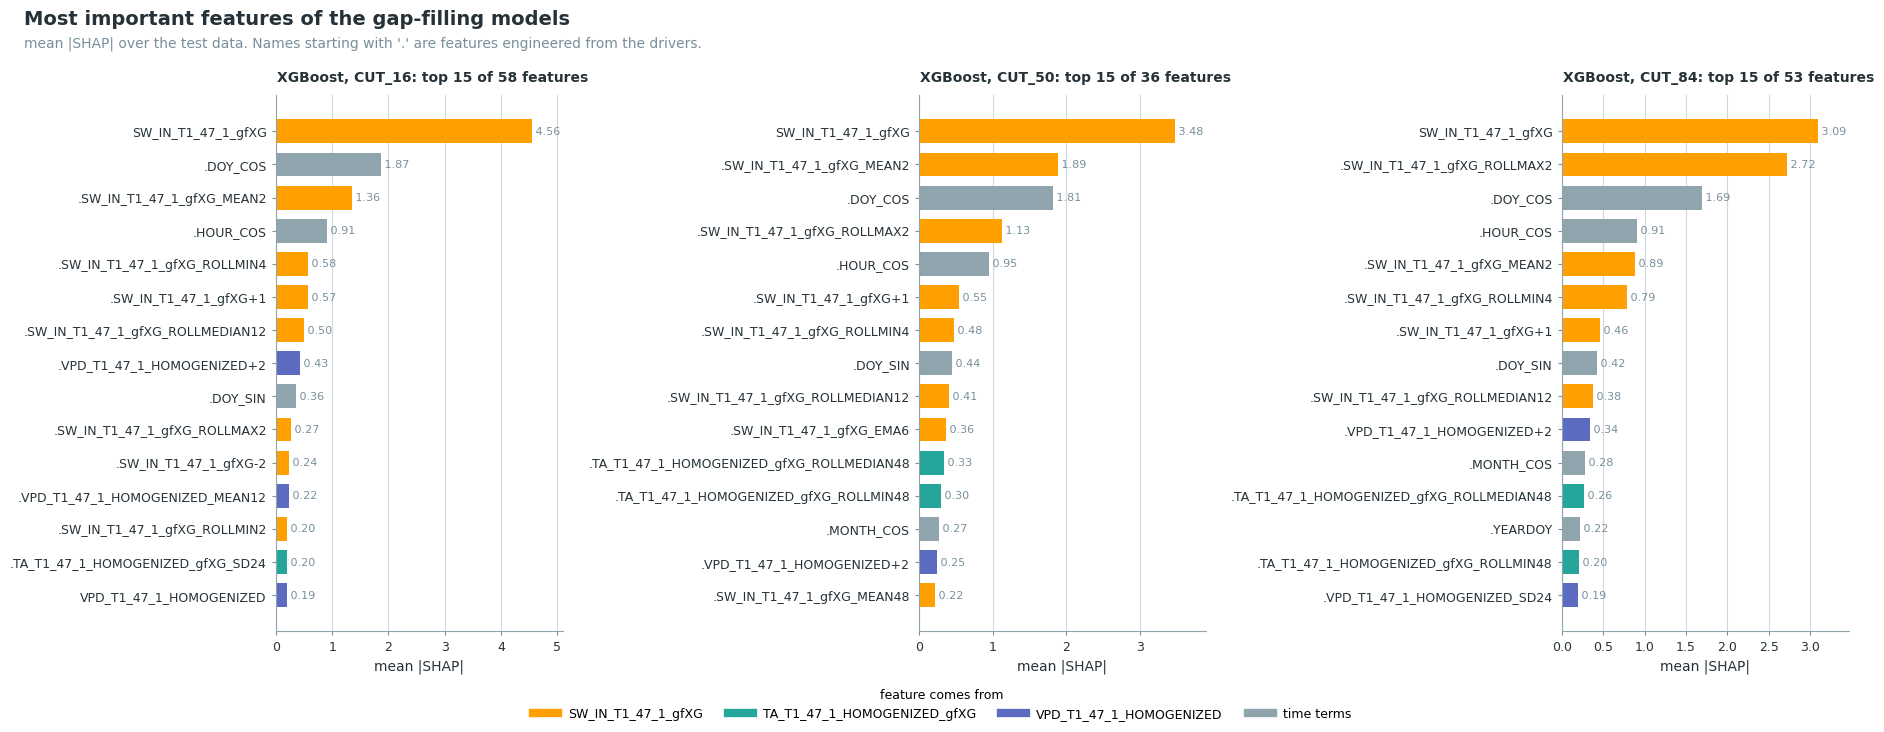

In [37]:
plot_feature_ranks_per_year(data)

## Step 11: result plots

### 📊 Plot: NEE by quality class, heatmaps, CUT_50

The highest-quality records (QCF 0), the records the gap-filling used (QCF 0 and 1), the rejected
records, and the gap-filled result, on one colour scale.

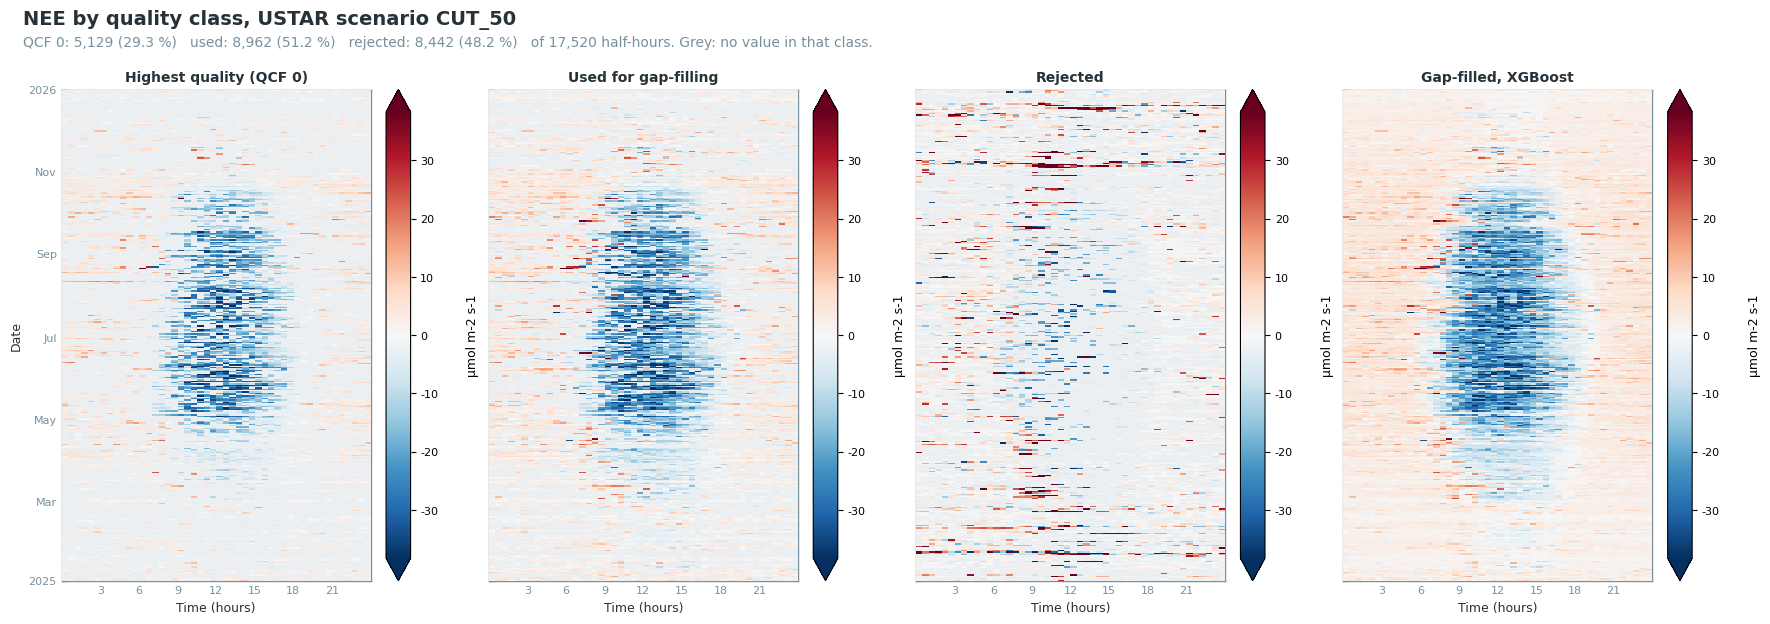

In [38]:
plot_quality_heatmaps(data, ustar_scenario='CUT_50', units=FLUX_UNITS)

### 📊 Plot: NEE by quality class, day and night, CUT_50

Daytime and nighttime records by quality class, then the gap-filled result with the measured and
the filled records apart.

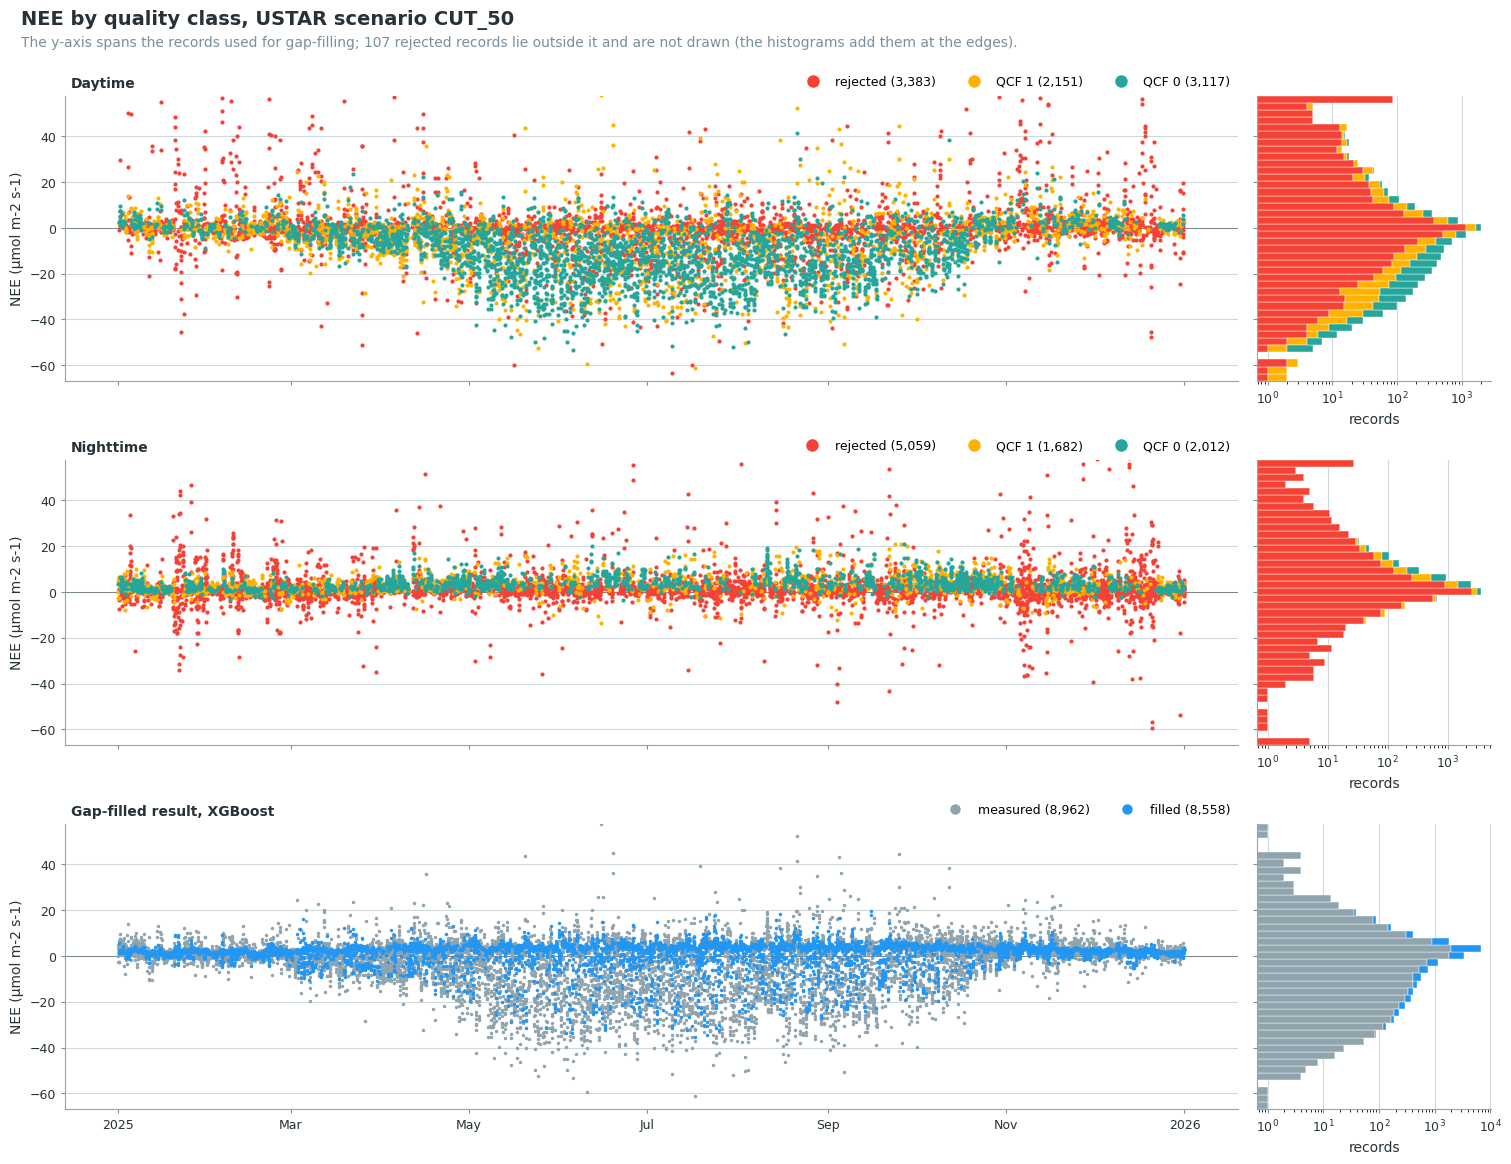

In [39]:
plot_quality_timeseries(data, ustar_scenario='CUT_50', units=FLUX_UNITS)

### 📊 Plot: measured and gap-filled NEE, CUT_50

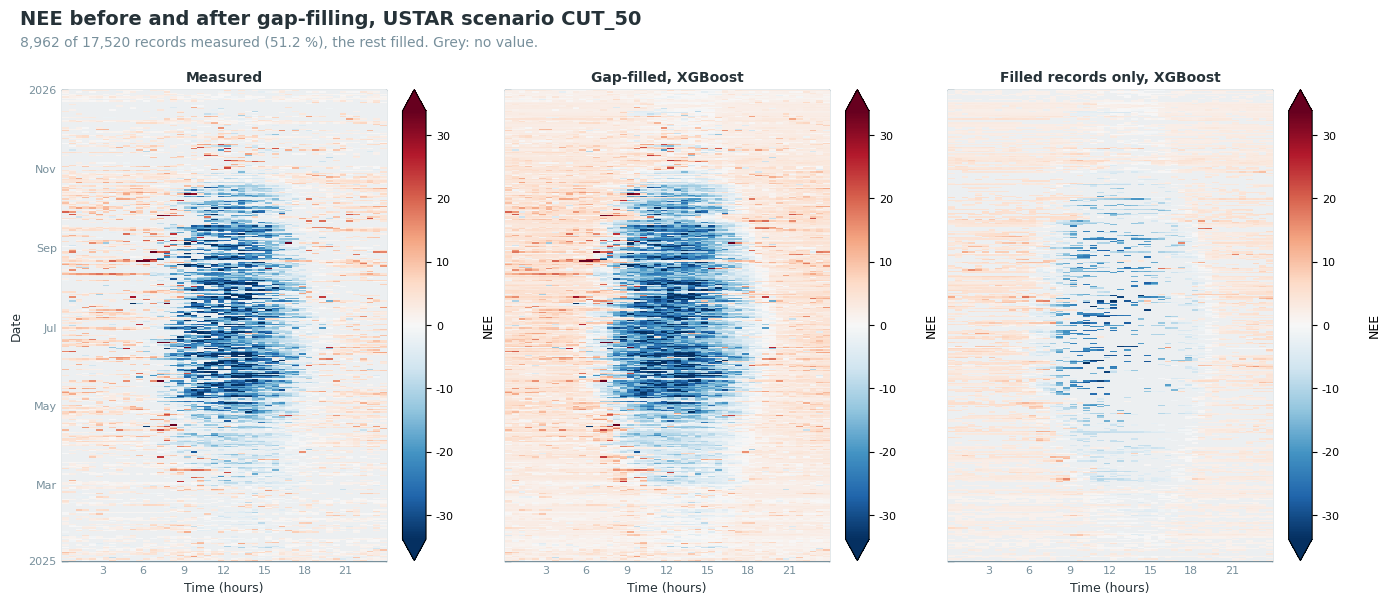

In [40]:
data.plot_gapfilled_heatmaps(ustar_scenario='CUT_50')

### 📊 Plot: cumulative NEE, CUT_50

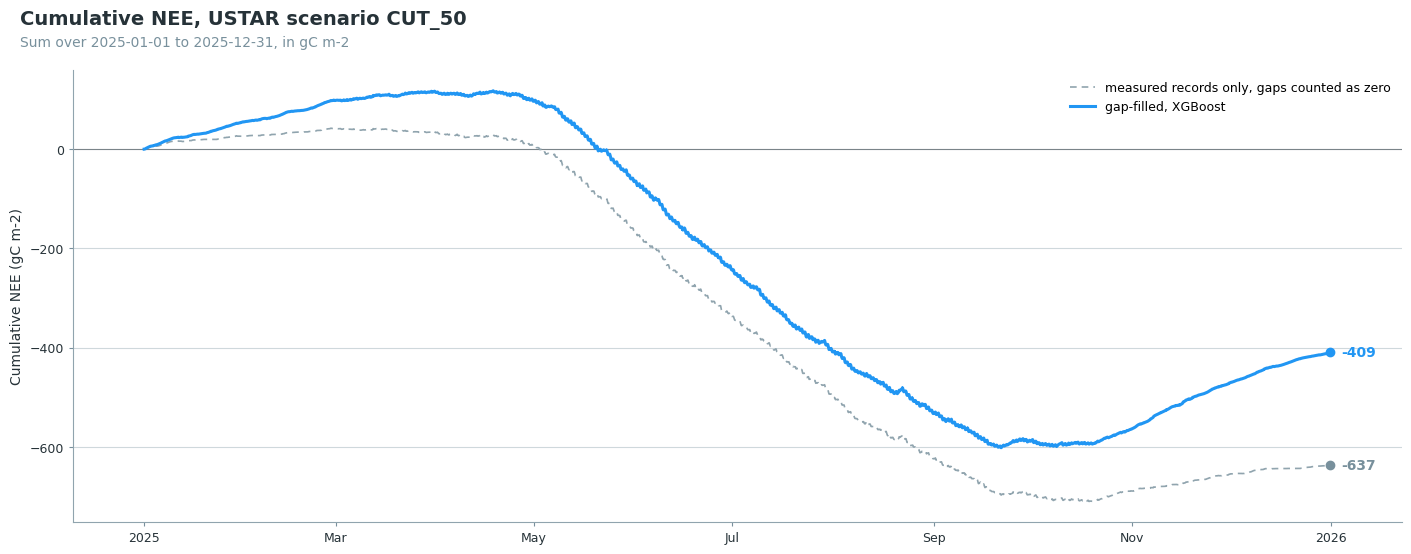

In [41]:
data.plot_cumulative_comparison(
    ustar_scenario='CUT_50',
    conv_factor=UMOL_TO_GC,
    units='gC m-2',
)

### 📊 Plot: cumulative NEE of all USTAR scenarios

One line per scenario. The spread between CUT_16, CUT_50 and CUT_84 shows how much the annual sum
depends on the USTAR threshold.

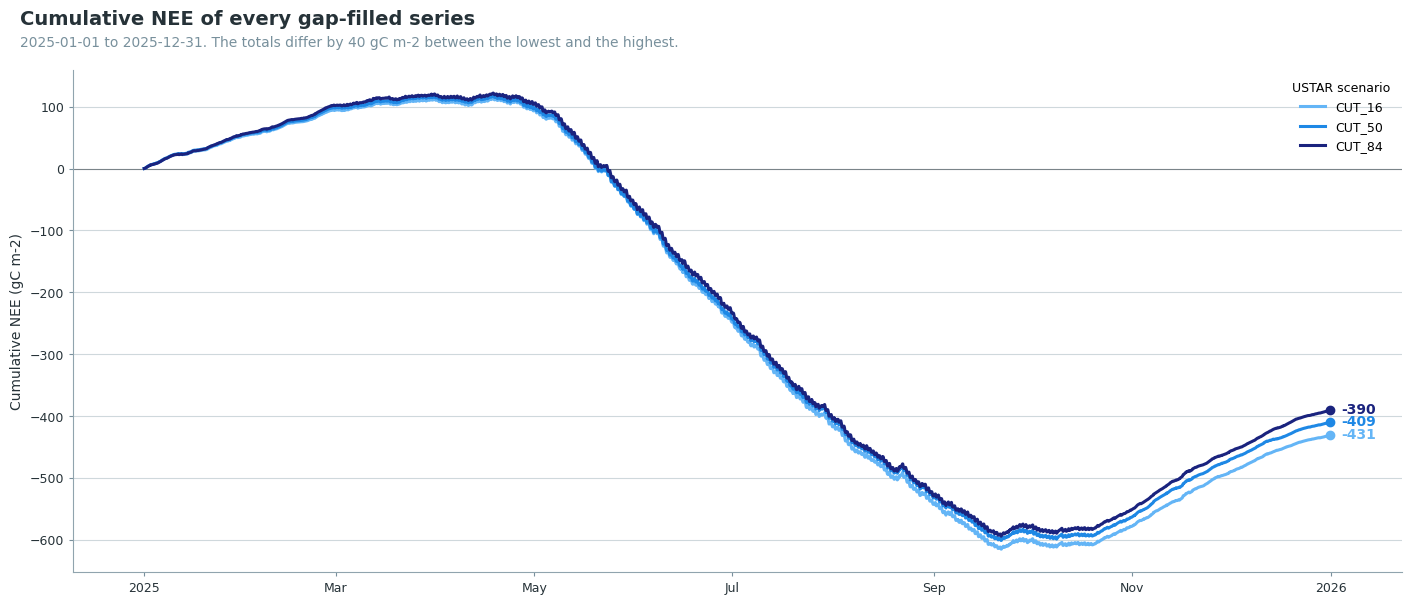

In [42]:
plot_gapfilled_cumulative(
    data,
    gain=UMOL_TO_GC,
    units='gC m-2',
    per_year=False,
)

### 📊 Plot: cumulative NEE per year, for each scenario

One line per year, with the range of all years as a band. 2016 starts on 11 January and 2026 ends on
30 September, so their totals cannot be compared with full years.

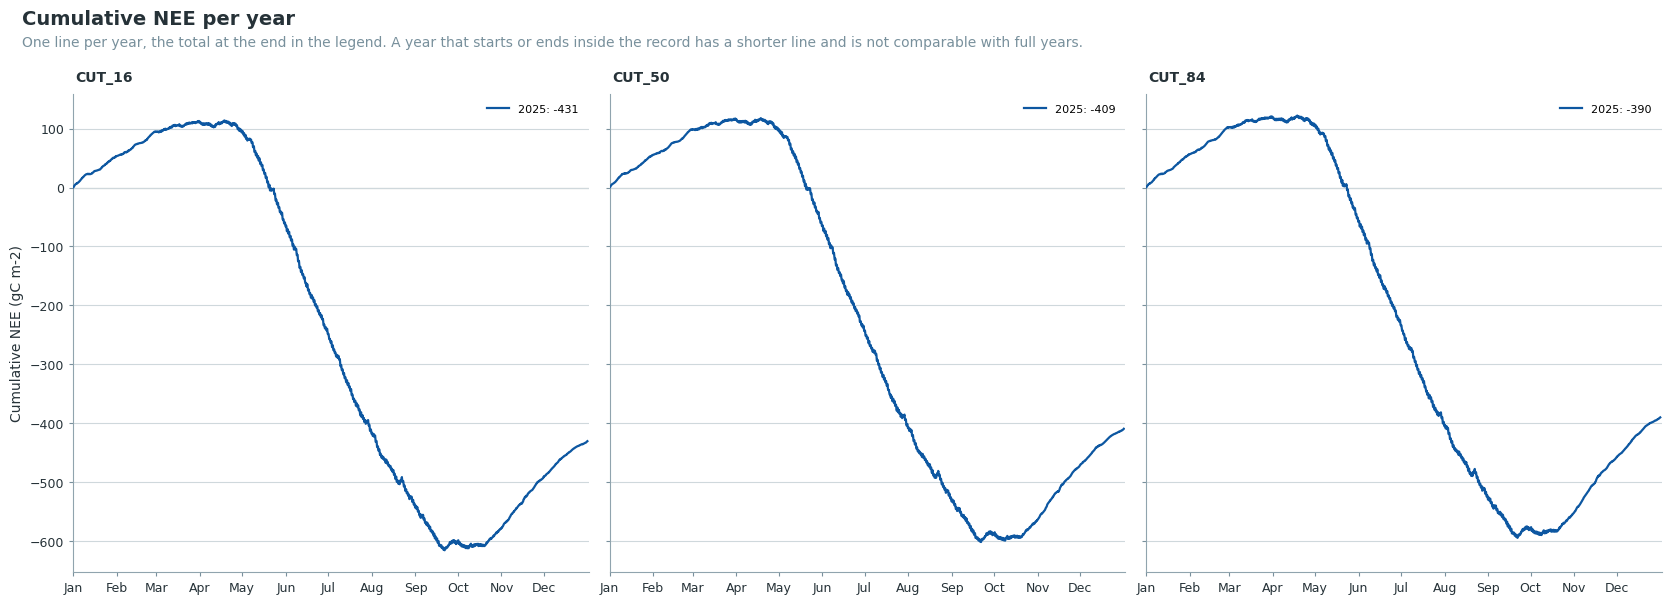

In [43]:
plot_gapfilled_cumulative(
    data,
    gain=UMOL_TO_GC,
    units='gC m-2',
    per_year=True,
)

## 💾 Step 12: export

`merged_df()` returns the input columns, unchanged, together with every column the chain added.

In [44]:
out_df = data.merged_df()
print(f"{out_df.shape[0]:,} records x {out_df.shape[1]} columns")
filepath = dv.save_parquet(data=out_df, filename=OUTNAME, outpath=OUTPATH)

> New variables from the flux post-processing chain: 57 (L2: 12, L3.1: 9, L3.2: 9, L3.3: 21, L4.1:
6)

> No variables in the input data were overwritten, only new variables added.

17,520 records x 409 columns


> Saved file 
F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\30_FLUX_PROCESSIN
G_CHAIN\34_IRGA72_2016-2024\01_FPPC_IRGA72_2016-2026.09_TEST_2025.parquet (0.377 seconds).

***

# End of notebook.

In [45]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-25 20:19:44
Finished: 2026-10-25 20:20:14
Runtime:  00:00:30 (hh:mm:ss)
